# 11 – Phase 3: augmentation against the test shift

**Goal:** reduce the gap between the clean and the shifted validation (baseline: OOF F1 0.844 clean / **0.820 shifted**, Kaggle 0.832) without hurting normal images, by showing the model during training the alterations found in the test.

Every experiment is **the baseline plus one change** (same model, hyper-parameters and folds), trained on all 5 folds (~12 min each):

| run | change | against |
|---|---|---|
| **E1** `e1_hue` | hue rotation, 50% of the training images, angle U(−180°, +180°) | hue-rotated test images (~28%) |
| **E2** `e2_blur` | Gaussian blur, 25% of the images, sigma U(0.1, 1.2) | blurred test images (~20%) |
| **E3** `e3_hue_blur` | E1 + E2 | both |
| **E4** `e4_hue_blur_bc_noise` | E3 + brightness/contrast (50%, ×0.8–1.2) + Gaussian noise (30%, std ≤ 0.03) | minor sky differences |

The augmentations use a **different implementation and wider ranges** than the shifted validation (PyTorch on the GPU, hue over the whole circle, sigma 0.1–1.2), so that the model learns a general robustness and not our exact simulation.

**Decision rule:** an experiment wins if the **shifted** OOF F1 rises by ≳ 0.01, the **clean** one does not drop by more than ~0.01 and class 4 does not collapse. One Kaggle submission at the end of the phase, with the winner.

All the code is in `train_lib.py`; the baseline is `run_experiment(baseline_config())`. Every experiment saves its results in `outputs/<run_name>/` as soon as it finishes: if the notebook stops, re-running it skips the completed experiments.

**Long run (≈ 50 min).** Either keep the Mac awake while it runs from VS Code, or run it on the PC inside `tmux`, which keeps going if you disconnect:
```
tmux new -s phase3
cd ~/ANN-DL-Challenge/families/elia && source ../../.venv/bin/activate
jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 11_phase3_augmentation.ipynb
```
Detach with `Ctrl+B` then `D`; reattach later with `tmux attach -t phase3`. When it finishes, open the notebook in VS Code: all outputs are saved in it.

## 0. Setup

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import train_lib as T
import common as C

plt.rcParams["figure.dpi"] = 80
SMOKE_TEST = False          # True = tiny run (few images, 1 epoch, fold 0) only to check that the code works
data = T.load_data(smoke_test=SMOKE_TEST)
print("device:", T.DEVICE, "| outputs:", T.OUT_DIR)

loaded 2995 training images (+ shifted versions) in 6s
device: cuda | outputs: /home/elia/ANN-DL-Challenge/families/elia/outputs


## 1. What the augmentations look like

Eight training images (top row) and, below, each augmentation applied **alone with probability 1**, then all together. During training each one is applied only to a fraction of the images (50% / 25% / 50% / 30%), with random strength.

**Check:** the galaxies must stay recognisable; colours change, sharpness changes, but the shape does not.

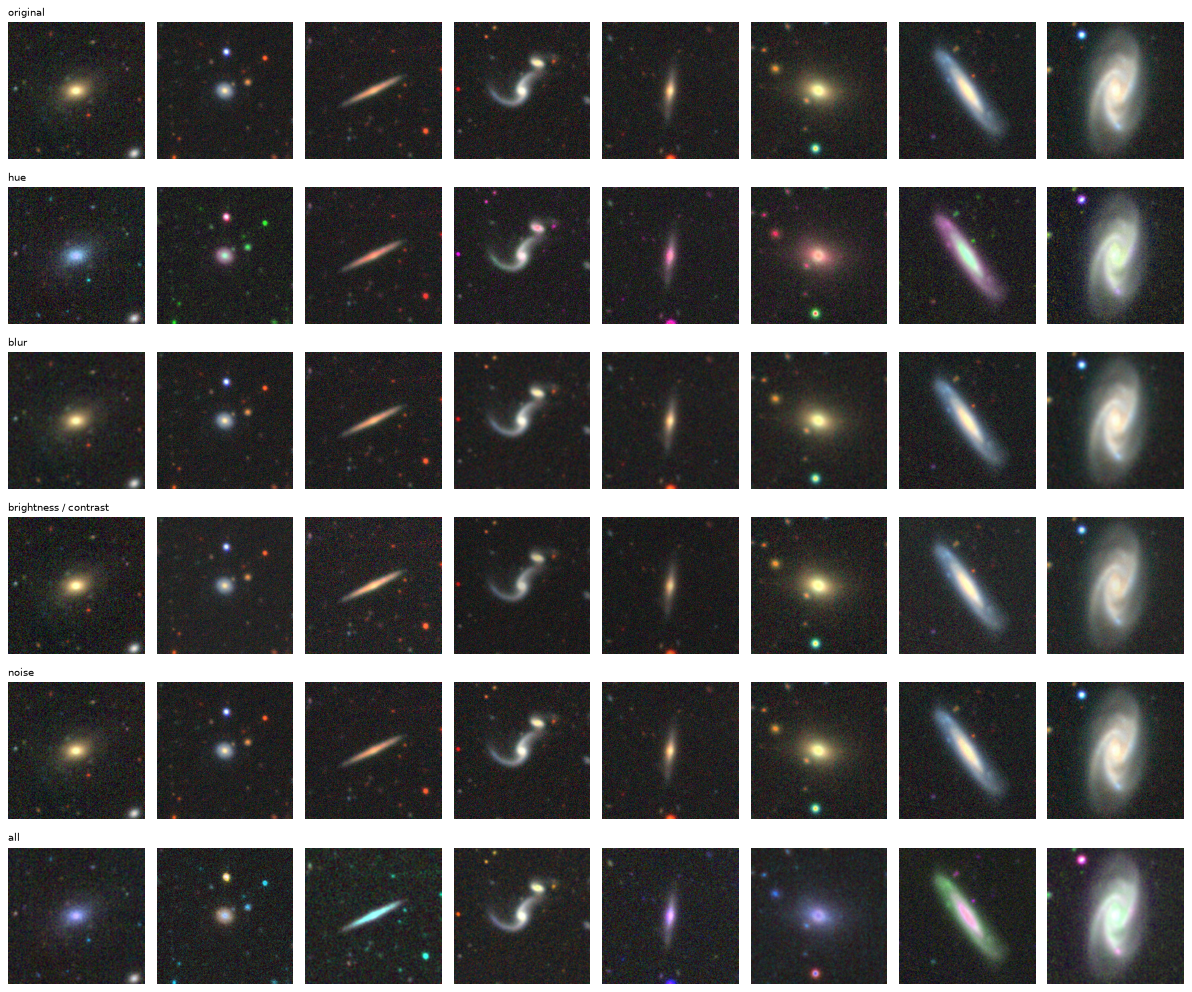

In [2]:
x0 = T.to_float(data["X_clean"][:8], 256)
variants = {
    "original": T.baseline_config(),
    "hue": T.baseline_config(hue_p=1.0),
    "blur": T.baseline_config(blur_p=1.0),
    "brightness / contrast": T.baseline_config(bc_p=1.0),
    "noise": T.baseline_config(noise_p=1.0),
    "all": T.baseline_config(hue_p=1.0, blur_p=1.0, bc_p=1.0, noise_p=1.0),
}
torch.manual_seed(0)
fig, axes = plt.subplots(len(variants), 8, figsize=(15, 2.1 * len(variants)))
for r, (name, cfg) in enumerate(variants.items()):
    xs = T.augment(x0.clone(), cfg).permute(0, 2, 3, 1).cpu().numpy()
    for c in range(8):
        axes[r, c].imshow(xs[c]); axes[r, c].axis("off")
    axes[r, 0].set_title(name, fontsize=9, loc="left")
plt.tight_layout(); plt.show()

## 2. The experiments

In [3]:
EXPERIMENTS = [
    T.baseline_config(run_name="e1_hue", note="+ hue rotation (p=0.5, ±180°)",
                      hue_p=0.5),
    T.baseline_config(run_name="e2_blur", note="+ gaussian blur (p=0.25, sigma 0.1-1.2)",
                      blur_p=0.25),
    T.baseline_config(run_name="e3_hue_blur", note="+ hue rotation + gaussian blur",
                      hue_p=0.5, blur_p=0.25),
    T.baseline_config(run_name="e4_hue_blur_bc_noise", note="+ hue + blur + brightness/contrast + noise",
                      hue_p=0.5, blur_p=0.25, bc_p=0.5, noise_p=0.3),
]
if SMOKE_TEST:
    for cfg in EXPERIMENTS:
        cfg.update(run_name=cfg["run_name"] + "_SMOKE", epochs=1, folds=[0], batch_size=16)

pd.DataFrame(EXPERIMENTS)[["run_name", "note", "hue_p", "blur_p", "bc_p", "noise_p", "epochs"]]

,run_name,note,hue_p,blur_p,bc_p,noise_p,epochs
0,e1_hue,"+ hue rotation (p=0.5, ±180°)",0.5,0.00,0.0,0.0,20
1,e2_blur,"+ gaussian blur (p=0.25, sigma 0.1-1.2)",0.0,0.25,0.0,0.0,20
2,e3_hue_blur,+ hue rotation + gaussian blur,0.5,0.25,0.0,0.0,20
3,e4_hue_blur_bc_noise,+ hue + blur + brightness/contrast + noise,0.5,0.25,0.5,0.3,20


In [4]:
results = {}
for cfg in EXPERIMENTS:
    results[cfg["run_name"]] = T.run_experiment(cfg, data)

loaded 14736 test images in 16s


e1_hue | fold 0 | epoch  1 | train loss 2.069 | F1 clean 0.437 | F1 shifted 0.440 | 22s
e1_hue | fold 0 | epoch  2 | train loss 1.507 | F1 clean 0.727 | F1 shifted 0.707 | 4s
e1_hue | fold 0 | epoch  3 | train loss 1.233 | F1 clean 0.757 | F1 shifted 0.743 | 4s
e1_hue | fold 0 | epoch  4 | train loss 1.112 | F1 clean 0.747 | F1 shifted 0.738 | 4s
e1_hue | fold 0 | epoch  5 | train loss 1.037 | F1 clean 0.791 | F1 shifted 0.789 | 4s
e1_hue | fold 0 | epoch  6 | train loss 0.972 | F1 clean 0.821 | F1 shifted 0.818 | 4s
e1_hue | fold 0 | epoch  7 | train loss 0.923 | F1 clean 0.825 | F1 shifted 0.811 | 4s
e1_hue | fold 0 | epoch  8 | train loss 0.882 | F1 clean 0.821 | F1 shifted 0.820 | 4s
e1_hue | fold 0 | epoch  9 | train loss 0.855 | F1 clean 0.826 | F1 shifted 0.820 | 4s
e1_hue | fold 0 | epoch 10 | train loss 0.825 | F1 clean 0.828 | F1 shifted 0.822 | 4s
e1_hue | fold 0 | epoch 11 | train loss 0.819 | F1 clean 0.828 | F1 shifted 0.822 | 4s
e1_hue | fold 0 | epoch 12 | train loss 0.

## 3. Comparison with the baseline

Out-of-fold weighted F1 on all 2,995 images, for the clean and the shifted validation, with the difference from the baseline (`Δ`). The **gap** is clean − shifted: the smaller, the more robust the model is to the test shift.

In [5]:
RUNS = [cfg["run_name"] for cfg in EXPERIMENTS]
table = T.compare(RUNS)
table.style.format("{:.4f}").background_gradient(subset=["Δ shifted"], cmap="RdYlGn", vmin=-0.02, vmax=0.02)

,F1 clean,F1 shifted,Δ clean,Δ shifted,gap (clean − shifted),cigar clean,cigar shifted
run,,,,,,,
baseline_convnext_tiny_256,0.8435,0.8200,0.0000,0.0000,0.0235,0.7692,0.7031
e1_hue,0.8456,0.8366,0.0021,0.0166,0.0090,0.7797,0.7742
e2_blur,0.8474,0.8310,0.0039,0.0110,0.0164,0.8034,0.7667
e3_hue_blur,0.8467,0.8458,0.0032,0.0258,0.0009,0.7863,0.7899
e4_hue_blur_bc_noise,0.8466,0.8436,0.0031,0.0235,0.0031,0.7863,0.7966


In [6]:
# per-class F1 on the shifted validation (and on the clean one below): where does each augmentation help or hurt?
names = ["baseline_convnext_tiny_256"] + RUNS
print("SHIFTED validation"); display(T.per_class(names, "shifted").round(3))
print("CLEAN validation");   display(T.per_class(names, "clean").round(3))

SHIFTED validation


,baseline_convnext_tiny_256,e1_hue,e2_blur,e3_hue_blur,e4_hue_blur_bc_noise
0 disturbed,0.419,0.439,0.436,0.465,0.444
1 merging,0.886,0.891,0.882,0.888,0.889
2 round smooth,0.926,0.925,0.928,0.936,0.935
3 in-between smooth,0.908,0.919,0.917,0.925,0.924
4 cigar,0.703,0.774,0.767,0.790,0.797
5 barred spiral,0.838,0.859,0.858,0.857,0.861
6 tight spiral,0.736,0.780,0.761,0.807,0.797
7 loose spiral,0.712,0.726,0.719,0.744,0.745
8 edge-on no bulge,0.901,0.926,0.912,0.921,0.924
9 edge-on bulge,0.916,0.927,0.924,0.932,0.926


CLEAN validation


,baseline_convnext_tiny_256,e1_hue,e2_blur,e3_hue_blur,e4_hue_blur_bc_noise
0 disturbed,0.474,0.462,0.474,0.468,0.469
1 merging,0.899,0.898,0.901,0.891,0.899
2 round smooth,0.930,0.932,0.933,0.930,0.931
3 in-between smooth,0.916,0.922,0.918,0.929,0.928
4 cigar,0.769,0.780,0.803,0.786,0.786
5 barred spiral,0.863,0.864,0.875,0.863,0.857
6 tight spiral,0.774,0.786,0.786,0.801,0.797
7 loose spiral,0.747,0.746,0.745,0.742,0.751
8 edge-on no bulge,0.918,0.925,0.916,0.921,0.920
9 edge-on bulge,0.939,0.938,0.940,0.942,0.931


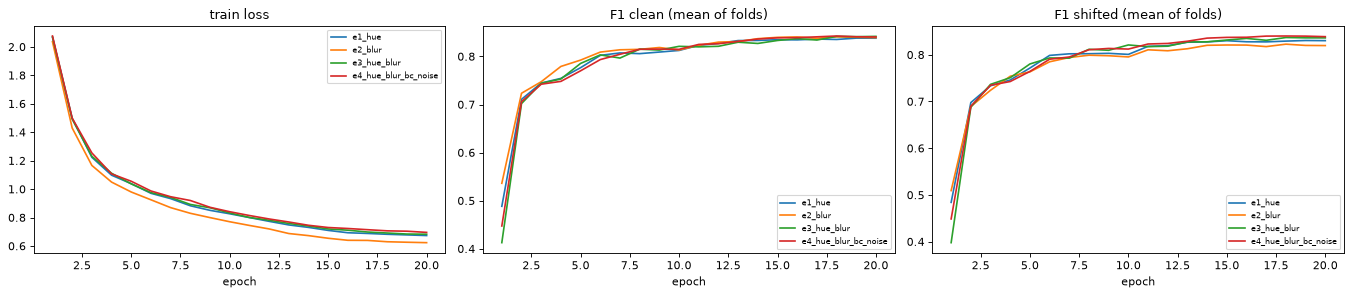

In [7]:
# mean training curves over the folds (shifted validation, no TTA)
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for name in RUNS:
    f = T.OUT_DIR / name / "history.csv"
    if not f.exists():
        continue
    h = pd.read_csv(f).groupby("epoch").mean(numeric_only=True)
    axes[0].plot(h.index, h.train_loss, label=name)
    axes[1].plot(h.index, h.f1_clean, label=name)
    axes[2].plot(h.index, h.f1_shifted, label=name)
for ax, t in zip(axes, ["train loss", "F1 clean (mean of folds)", "F1 shifted (mean of folds)"]):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**How to read the curves.** With more augmentation the training loss stays higher (the task is harder): this is expected. What matters is the validation, especially the shifted one. If a curve is **still rising at epoch 20**, the experiment may need more epochs (a test for the next phase).

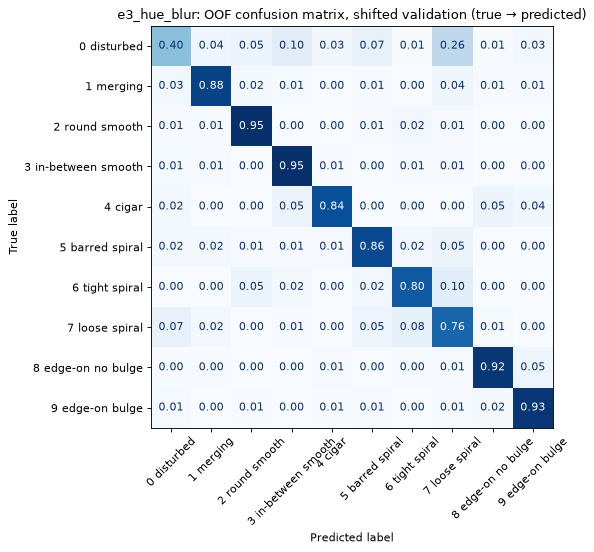

In [8]:
# confusion matrix (shifted validation) of the best run on the shifted validation
from sklearn.metrics import ConfusionMatrixDisplay
best = table["F1 shifted"].idxmax()
s = T.oof_scores(best)["shifted"]
cm = s["confusion"] / s["confusion"].sum(1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=[f"{c} {C.CLASSES[c]}" for c in range(10)]).plot(
    ax=ax, values_format=".2f", cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_title(f"{best}: OOF confusion matrix, shifted validation (true → predicted)")
plt.tight_layout(); plt.show()

## 4. Decision

Apply the rule to the table above:
1. **E1 / E2:** each one alone — does the shifted F1 rise by ≳ 0.01? Does the clean F1 stay within ~0.01?
2. **E3:** is the combination better than the best single one? (If E2 did not help, the reference is E1 alone.)
3. **E4:** do brightness/contrast/noise add anything on top?

The winner's submission is in `outputs/<run_name>/submission.csv`: submit **only that one** to Kaggle and write its public score in the `kaggle` column of its `OOF` row in `experiments_log.csv`.

Results (fill in):
- E1: shifted ___ (Δ ___), clean ___ (Δ ___)
- E2: shifted ___ (Δ ___), clean ___ (Δ ___)
- E3: shifted ___ (Δ ___), clean ___ (Δ ___)
- E4: shifted ___ (Δ ___), clean ___ (Δ ___)
- **Winner:** ___ → Kaggle public ___